# Multilayer local score with an entropy-barrier window: does it raise Inception Score?

**Run:** 2026-10-21, commit `2c2dc90` (+ `--scale_multiplier` control, commit noted in the
config cell below). Seed 0, 500 samples per configuration, Inception Score over 5 splits.

### The model

`MultilayerLocalScoreModule` adds a second layer on top of the existing `LocalScoreModule`:

1. Layer 1 is plain LS: a per-pixel Gaussian posterior over training patches in a $k_1\times k_1$
   window gives $\hat{x}_1$.
2. Layer 2 sees **only** $\hat{x}_1$. Using a larger window $k_2$ it forms a posterior
   $w_n(p)$ over all training images $n$, and adds the expected error of the layer-1 estimate,
   $\;\delta(p) = \sum_n w_n(p)\,\bigl(x_n(p) - \hat{x}_1(p)\bigr)$.
3. The full estimate is $\hat{x} = \hat{x}_1 + \delta$, converted to a score by the usual
   convention $s = (a_t\hat{x} - x)/b_t^2$.

`EntropyBarrierMLSModule` chooses $k_2$ at every denoising step: the **largest** candidate window
whose layer-2 posterior entropy is still $\ge$ `barrier` nats. Entropy falls as the window grows
(a big window matches one training image and the posterior collapses), so the barrier is a floor on
how much of the training set the layer is still averaging over.

> **Wording check for hshunt.** The request was "the large length scale that stays *below* some
> posterior entropy barrier". Entropy *decreases* with $k$ here, so "largest $k$ below the barrier"
> is degenerate — it always selects the biggest candidate. This implements the non-degenerate
> reading: the largest scale that has *not yet* collapsed onto a single training image. If you
> meant the other one, it is a one-line flip of the comparison.

### What this notebook has to settle

IS can be bought outright with memorization: real CIFAR-10 images score 8.75 on this eval, so any
model that copies the training set wins. Every run therefore also reports the median RMS distance
from each sample to its nearest training image (same class when conditional), and the fraction of
samples within 0.05 RMS of one. **The claim to test is not "higher IS" but "higher IS at matched
distance to the training set"**, against plain LS with its windows scaled up as the control.

Each run additionally reports **FID and KID**, added after the fact from the saved samples
(`scripts/add_fid.py`). This matters more than it sounds: IS has almost no dynamic range on CelebA
(real images score 3.31) or MNIST (1.92), because an ImageNet classifier has nothing to say about
faces or digits, so "no IS change" on those datasets is unreadable. FID compares feature
*distributions* against the real data and stays informative. It changed a conclusion — see below.

## Load every run

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
RES = ROOT / 'results' / 'mls_inception'

RUNS = []
for f in sorted(RES.glob('2026-10-2*/*/metrics.json')):
    m = json.load(open(f))
    m['run'], m['dir'] = f.parent.name, f.parent
    m['mult'] = m.get('scale_multiplier') or 1.0
    m['seed'] = 1 if f.parent.name.endswith('seed1') else 0
    half = '' if m.get('mult_half', 'all') in (None, 'all') else f", {m['mult_half']}-noise half only"
    m['hi'] = m.get('scale_multiplier_hi')
    m['flat'], m['gamma'] = m.get('flat_k'), m.get('scale_gamma')
    # Each schedule *shape* is its own family with its own frontier curve: up- and down-ramps
    # move in opposite directions, and the flat and gamma runs carry scale_multiplier 1.0 and
    # 2.0, so without this they would be read as plain uniform runs at those multipliers.
    m['family'] = ('LSflat' if m['flat'] else 'LSgamma' if m['gamma'] is not None else
                   ('LSramp_down' if m['mult'] > m['hi'] else 'LSramp_up') if m['hi'] else m['method'])
    m['config'] = ('real images' if m['method'] == 'real' else
                   f"LS (flat k={m['flat']})" if m['flat'] else
                   f"LS (gamma {m['gamma']:g} at x{m['mult']:g})" if m['gamma'] is not None else
                   f"LS (ramp x{m['mult']:g}→x{m['hi']:g})" if m['hi'] else
                   ('LS' if m['mult'] == 1.0 else f"LS (windows x{m['mult']:g}{half})") if m['method'] == 'LS' else
                   f"EBMLS barrier {m['barrier']:g}")
    RUNS.append(m)


def sel(dataset=None, method=None, family=None, mult=None, seed=0, half='all', sort=None):
    """half='all' keeps only the full-trajectory runs, so the split-half runs stay off the curves."""
    out = [r for r in RUNS
           if (dataset is None or r['dataset'] == dataset)
           and (method is None or r['method'] == method)
           and (family is None or r['family'] == family)
           and (mult is None or r['mult'] == mult)
           and (seed is None or r['seed'] == seed)
           and (half is None or (r.get('mult_half') or 'all') == half)]
    return sorted(out, key=lambda r: r[sort] if r[sort] is not None else 0) if sort else out


DSETS = [d for d in ['cifar10', 'mnist', 'celeba'] if sel(dataset=d)]
# cwd=, not `git -C`: the stock Sherlock git is 1.8.3.1 and has no -C.
print(f'{len(RUNS)} runs over {DSETS}; commit '
      + subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT),
                       capture_output=True, text=True).stdout.strip())

52 runs over ['cifar10', 'mnist', 'celeba']; commit b3f6d99


## Metrics

`IS` is the Inception Score (higher = better, 5 splits; the $\pm$ is the split spread, not a seed
spread — with 500 samples it understates run-to-run variation). `NN-RMS` is the median distance to
the nearest training image in normalized pixel units (**higher = less like the training set**);
`copy` is the fraction of samples within 0.05 RMS of a training image.

In [2]:
ORDER = {'real': 0, 'LS': 1, 'LSramp_down': 2, 'LSramp_up': 3, 'LSgamma': 4, 'LSflat': 5,
         'MLS': 6, 'EBMLS': 7}
hdr = (f"{'dataset':8s} {'configuration':24s} {'seed':>4s} {'IS ↑':>14s} {'FID ↓':>7s} "
       f"{'KID ↓':>7s} {'NN-RMS':>7s} {'copy':>6s}")
print(hdr + '\n' + '-' * len(hdr))
for r in sorted(RUNS, key=lambda r: (r['dataset'], ORDER[r['family']], r['mult'], r['barrier'] or 0, r['seed'])):
    nn = '   —  ' if r['nn_rms_median'] is None else f"{r['nn_rms_median']:7.3f}"
    cp = '  —  ' if r['copy_fraction'] is None else f"{r['copy_fraction']:6.3f}"
    fid = '   —  ' if r.get('FID') is None else f"{r['FID']:7.2f}"
    kid = '   —  ' if r.get('KID_mean') is None else f"{r['KID_mean']:7.4f}"
    print(f"{r['dataset']:8s} {r['config']:24s} {r['seed']:4d} "
          f"{r['IS_mean']:7.3f} ± {r['IS_std']:.3f} {fid} {kid} {nn} {cp}")

dataset  configuration            seed           IS ↑   FID ↓   KID ↓  NN-RMS   copy
------------------------------------------------------------------------------------
celeba   real images                 0   3.307 ± 0.119   32.84 -0.0002    —     —  
celeba   LS                          0   2.393 ± 0.043  128.27  0.1219   0.357  0.000
celeba   LS (windows x1.5)           0   2.399 ± 0.214  101.04  0.0851   0.321  0.000
celeba   LS (windows x2)             0   2.344 ± 0.090   79.37  0.0579   0.302  0.000
celeba   LS (ramp x3.4→x1.6)         0   2.344 ± 0.193   70.02  0.0439   0.301  0.000
celeba   EBMLS barrier 1             0   1.644 ± 0.031  127.95  0.1239   0.172  0.000
celeba   EBMLS barrier 2             0   1.617 ± 0.028  142.44  0.1414   0.192  0.000
celeba   EBMLS barrier 4             0   1.796 ± 0.106  136.28  0.1333   0.216  0.000
cifar10  real images                 0   8.753 ± 0.465   54.93 -0.0004    —     —  
cifar10  LS                          0   2.777 ± 0.157  188.

## Figure 1 — IS against the barrier

The LS baseline (dashed) is the previous best on this eval; the real-image ceiling (dotted) is what
pure memorization would score.

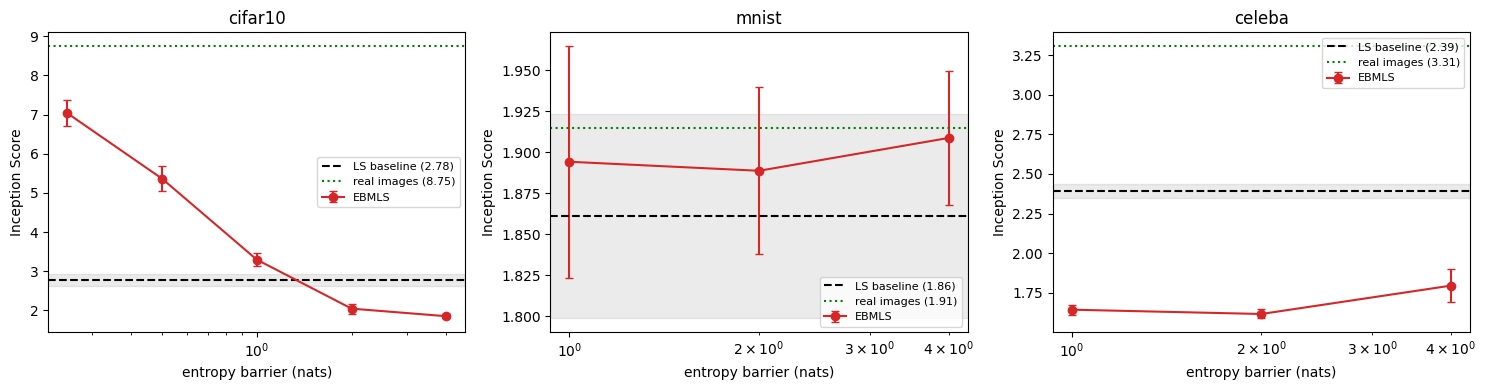

In [3]:
fig, axes = plt.subplots(1, len(DSETS), figsize=(5 * len(DSETS), 4), squeeze=False)
for ax, d in zip(axes[0], DSETS):
    eb = sel(dataset=d, method='EBMLS', sort='barrier')
    if eb:
        ax.errorbar([r['barrier'] for r in eb], [r['IS_mean'] for r in eb],
                    yerr=[r['IS_std'] for r in eb], marker='o', capsize=3, c='C3', label='EBMLS')
    ls = sel(dataset=d, family='LS', mult=1.0)
    if ls:
        ax.axhline(ls[0]['IS_mean'], ls='--', c='k', label=f"LS baseline ({ls[0]['IS_mean']:.2f})")
        ax.axhspan(*(ls[0]['IS_mean'] + np.array([-1, 1]) * ls[0]['IS_std']), color='k', alpha=.08)
    rl = sel(dataset=d, method='real')
    if rl:
        ax.axhline(rl[0]['IS_mean'], ls=':', c='g', label=f"real images ({rl[0]['IS_mean']:.2f})")
    ax.set_xscale('log'); ax.set_xlabel('entropy barrier (nats)'); ax.set_ylabel('Inception Score')
    ax.set_title(d); ax.legend(fontsize=8)
fig.tight_layout()

## Figure 2 — the figure that decides it: IS against distance to the training set

Every point is one configuration. Right = samples are far from the training set (not copying);
up = higher IS. A method only beats the baseline if it sits **above the single-layer LS curve at the
same x**. The LS points at several window multipliers trace that single-layer frontier.

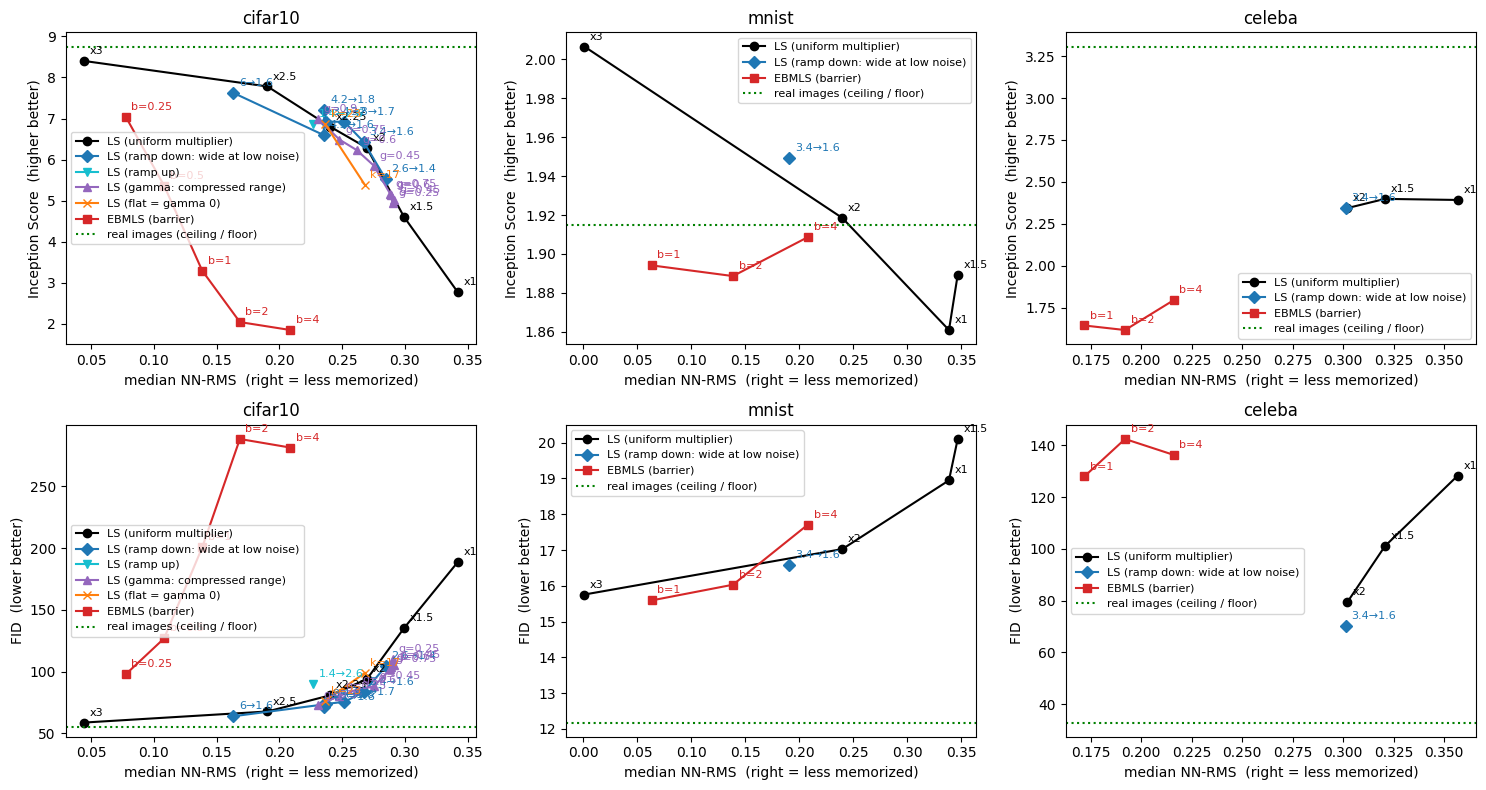

In [4]:
fig, axes = plt.subplots(2, len(DSETS), figsize=(5 * len(DSETS), 8), squeeze=False)
for col, d in enumerate(DSETS):
    for row, (ykey, ylab) in enumerate([('IS_mean', 'Inception Score  (higher better)'),
                                        ('FID', 'FID  (lower better)')]):
        ax = axes[row][col]
        for fam, c, mk, lab in [('LS', 'k', 'o-', 'LS (uniform multiplier)'),
                                ('LSramp_down', 'C0', 'D-', 'LS (ramp down: wide at low noise)'),
                                ('LSramp_up', 'C9', 'v-', 'LS (ramp up)'),
                                ('LSgamma', 'C4', '^-', 'LS (gamma: compressed range)'),
                                ('LSflat', 'C1', 'x-', 'LS (flat = gamma 0)'),
                                ('EBMLS', 'C3', 's-', 'EBMLS (barrier)')]:
            s = [r for r in sorted(sel(dataset=d, family=fam), key=lambda r: r['nn_rms_median'])
                 if r.get(ykey) is not None]
            if not s:
                continue
            ax.plot([r['nn_rms_median'] for r in s], [r[ykey] for r in s], mk, c=c, label=lab)
            for r in s:
                tag = (f"b={r['barrier']:g}" if fam == 'EBMLS' else
                       f"k={r['flat']}" if r['flat'] else
                       f"g={r['gamma']:g}" if r['gamma'] is not None else
                       f"{r['mult']:g}→{r['hi']:g}" if r['hi'] else f"x{r['mult']:g}")
                ax.annotate(tag, (r['nn_rms_median'], r[ykey]), fontsize=8, color=c,
                            xytext=(4, 5), textcoords='offset points')
        rl = sel(dataset=d, method='real')
        if rl and rl[0].get(ykey) is not None:
            ax.axhline(rl[0][ykey], ls=':', c='g', label='real images (ceiling / floor)')
        ax.set_xlabel('median NN-RMS  (right = less memorized)')
        ax.set_ylabel(ylab); ax.set_title(d); ax.legend(fontsize=8)
fig.tight_layout()

## Figure 2b — which denoising steps does the window-width gain come from?

`scales[i]` is the window at $t=i/\mathrm{nsteps}$, so the list runs low-noise → high-noise.
These runs apply the ×2 multiplier to only half of it, leaving the other half at baseline.

baseline (x1)                IS  2.777   FID  188.69   copies 0.000
x2 on hi-noise half          IS  3.061   FID  179.25   copies 0.000
x2 on lo-noise half          IS  3.997   FID  146.80   copies 0.000
x2 everywhere                IS  6.286   FID   93.96   copies 0.000


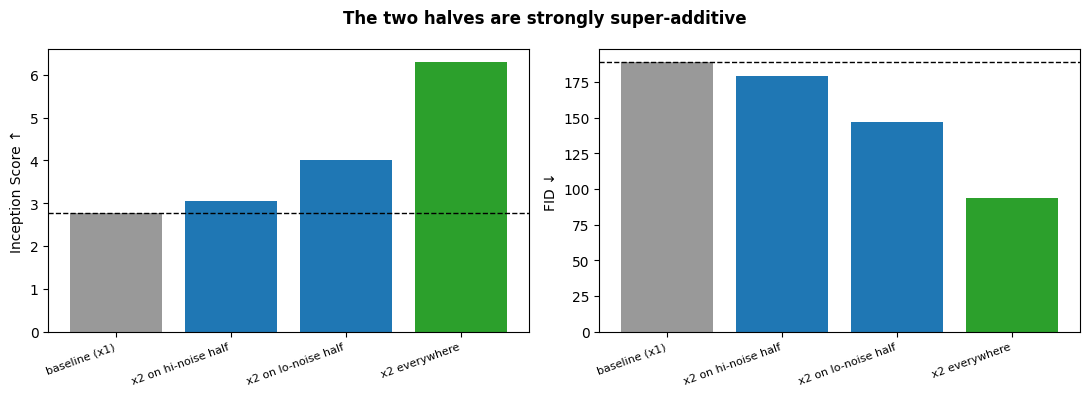

In [5]:
split = [r for r in RUNS if (r.get('mult_half') or 'all') != 'all']
base = sel(dataset='cifar10', family='LS', mult=1.0)
full = sel(dataset='cifar10', family='LS', mult=2.0)
if split:
    labels, vals = [], []
    for r in [base[0]] + sorted(split, key=lambda r: r['mult_half']) + [full[0]]:
        labels.append({'all': 'x2 everywhere'}.get(r.get('mult_half') or 'all', '')
                      or (f"x2 on {r['mult_half']}-noise half" if r['mult'] > 1 else 'baseline (x1)'))
        vals.append(r)
    labels[0], labels[-1] = 'baseline (x1)', 'x2 everywhere'
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, (key, lab) in zip(axes, [('IS_mean', 'Inception Score ↑'), ('FID', 'FID ↓')]):
        y = [r.get(key) for r in vals]
        if any(v is None for v in y):
            ax.set_title(f'{lab} — not yet computed'); continue
        ax.bar(range(len(y)), y, color=['.6', 'C0', 'C0', 'C2'])
        ax.axhline(y[0], ls='--', c='k', lw=1)
        ax.set_xticks(range(len(y))); ax.set_xticklabels(labels, rotation=20, ha='right', fontsize=8)
        ax.set_ylabel(lab)
    fig.suptitle('The two halves are strongly super-additive', fontweight='bold')
    fig.tight_layout()
    for lab, r in zip(labels, vals):
        print(f"{lab:28s} IS {r['IS_mean']:6.3f}   FID {r.get('FID') or float('nan'):7.2f}   "
              f"copies {r['copy_fraction']:.3f}")
else:
    print('no split-half runs found')

## Figure 2c — the shape of the schedule, not just its overall width

Super-additivity rules out widening *half* the trajectory, but it does not show that a **uniform**
multiplier is the best shape. These runs ramp the multiplier linearly from $m_0$ at $t=0$ to $m_1$
at $t=1$ (a ramp rather than a step at the midpoint, since a step drops the window from 19 to 11
across the seam and would confound the tilt with a broken coarse-to-fine ordering).

A *down*-ramp loads the extra width onto the low-noise end and flattens the base schedule; an
*up*-ramp steepens it. Left: the resulting window schedules. Right: where each lands on the
FID-vs-memorization frontier, against the uniform family.

LS                         seed 0  NN-RMS 0.342  IS  2.777  FID  188.69  copies 0.000
LS (gamma 0.45 at x2)      seed 0  NN-RMS 0.291  IS  5.016  FID  105.30  copies 0.000
LS (gamma 0.25 at x2)      seed 0  NN-RMS 0.290  IS  4.941  FID  110.12  copies 0.000
LS (gamma 0.6 at x2)       seed 0  NN-RMS 0.289  IS  5.151  FID  103.63  copies 0.000
LS (gamma 0.75 at x2)      seed 0  NN-RMS 0.288  IS  5.167  FID  101.82  copies 0.000
LS (ramp x2.6→x1.4)        seed 0  NN-RMS 0.285  IS  5.519  FID  104.37  copies 0.000
LS (gamma 0.45 at x2.5)    seed 0  NN-RMS 0.275  IS  5.855  FID   88.11  copies 0.002
LS (windows x2)            seed 0  NN-RMS 0.270  IS  6.286  FID   93.96  copies 0.000
LS (flat k=17)             seed 0  NN-RMS 0.268  IS  5.384  FID   99.00  copies 0.000
LS (ramp x3.4→x1.6)        seed 0  NN-RMS 0.267  IS  6.437  FID   83.27  copies 0.002
LS (gamma 0.6 at x2.5)     seed 0  NN-RMS 0.262  IS  6.232  FID   85.45  copies 0.004
LS (ramp x3.8→x1.7)        seed 0  NN-RMS 0.252  IS  6

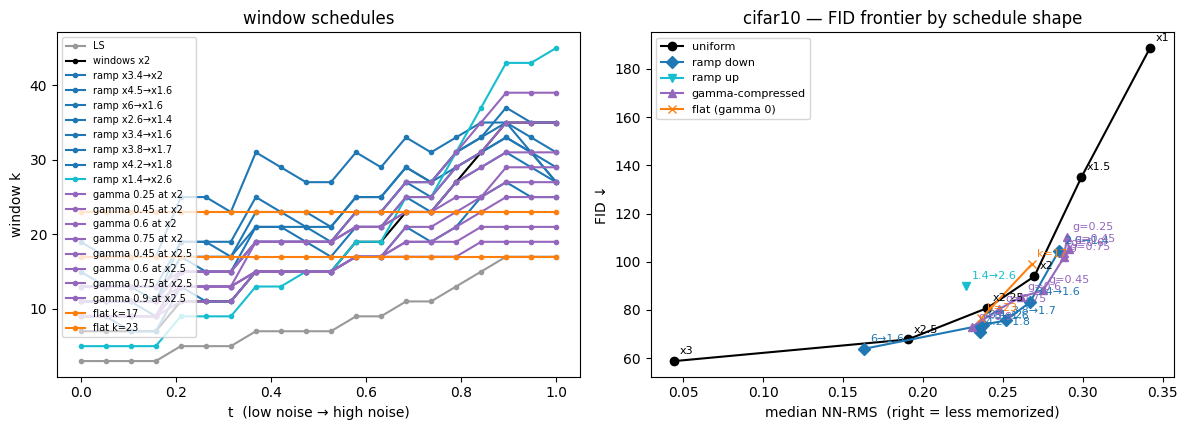

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
COLOUR = {'LS': 'k', 'LSramp_down': 'C0', 'LSramp_up': 'C9', 'LSgamma': 'C4', 'LSflat': 'C1'}
show = (sel(dataset='cifar10', family='LS', mult=1.0) + sel(dataset='cifar10', family='LS', mult=2.0)
        + sel(dataset='cifar10', family='LSramp_down') + sel(dataset='cifar10', family='LSramp_up')
        + sel(dataset='cifar10', family='LSgamma') + sel(dataset='cifar10', family='LSflat'))
for r in show:
    k = r['scales']
    axes[0].plot(np.arange(len(k)) / (len(k) - 1), k, marker='.',
                 c='.6' if r['family'] == 'LS' and r['mult'] == 1.0 else COLOUR[r['family']],
                 label=r['config'].replace('LS ', '').strip('()'))
axes[0].set_xlabel('t  (low noise → high noise)'); axes[0].set_ylabel('window k')
axes[0].legend(fontsize=7); axes[0].set_title('window schedules')

for fam, mk, lab in [('LS', 'o-', 'uniform'), ('LSramp_down', 'D-', 'ramp down'),
                     ('LSramp_up', 'v-', 'ramp up'), ('LSgamma', '^-', 'gamma-compressed'),
                     ('LSflat', 'x-', 'flat (gamma 0)')]:
    s = [r for r in sorted(sel(dataset='cifar10', family=fam), key=lambda r: r['nn_rms_median'])
         if r.get('FID') is not None]
    if s:
        axes[1].plot([r['nn_rms_median'] for r in s], [r['FID'] for r in s], mk, c=COLOUR[fam], label=lab)
        for r in s:
            axes[1].annotate(f"k={r['flat']}" if r['flat'] else f"g={r['gamma']:g}" if r['gamma'] is not None
                             else f"{r['mult']:g}→{r['hi']:g}" if r['hi'] else f"x{r['mult']:g}",
                             (r['nn_rms_median'], r['FID']), fontsize=8, color=COLOUR[fam],
                             xytext=(4, 5), textcoords='offset points')
axes[1].set_xlabel('median NN-RMS  (right = less memorized)'); axes[1].set_ylabel('FID ↓')
axes[1].legend(fontsize=8); axes[1].set_title('cifar10 — FID frontier by schedule shape')
fig.tight_layout()

for r in sorted(show, key=lambda r: -r['nn_rms_median']):
    print(f"{r['config']:26s} seed {r['seed']}  NN-RMS {r['nn_rms_median']:.3f}  "
          f"IS {r['IS_mean']:6.3f}  FID {r.get('FID') or float('nan'):7.2f}  copies {r['copy_fraction']:.3f}")

## Figure 3 — the window schedule the barrier produces

`layer2_k_by_t` is the average layer-2 window the barrier selected at each denoising step
($k=0$ means no candidate passed, so the step is plain LS). Nothing imposes a schedule; it falls
out of the entropy constraint.

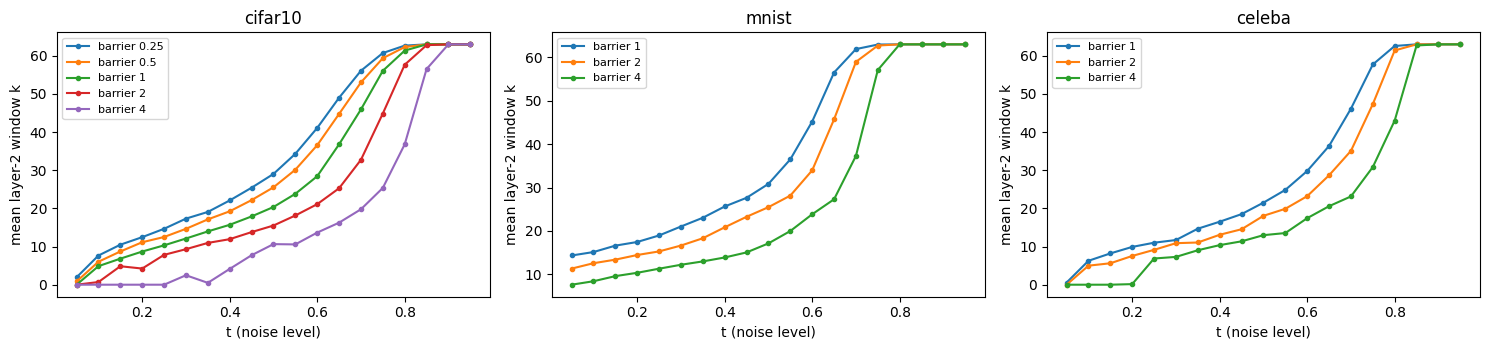

In [7]:
fig, axes = plt.subplots(1, len(DSETS), figsize=(5 * len(DSETS), 3.6), squeeze=False)
for ax, d in zip(axes[0], DSETS):
    for r in sel(dataset=d, method='EBMLS', sort='barrier'):
        kk = r['layer2_k_by_t'] or {}
        if kk:
            ax.plot([float(x) for x in kk], list(kk.values()), marker='.', label=f"barrier {r['barrier']:g}")
    ax.set_xlabel('t (noise level)'); ax.set_ylabel('mean layer-2 window k')
    ax.set_title(d); ax.legend(fontsize=8)
fig.tight_layout()

## Figure 4 — how close the samples get to the training set

/tmp/ipykernel_70561/2024848136.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ax.hist(torch.load(p).numpy(), bins=40, histtype='step', label=r['config'])


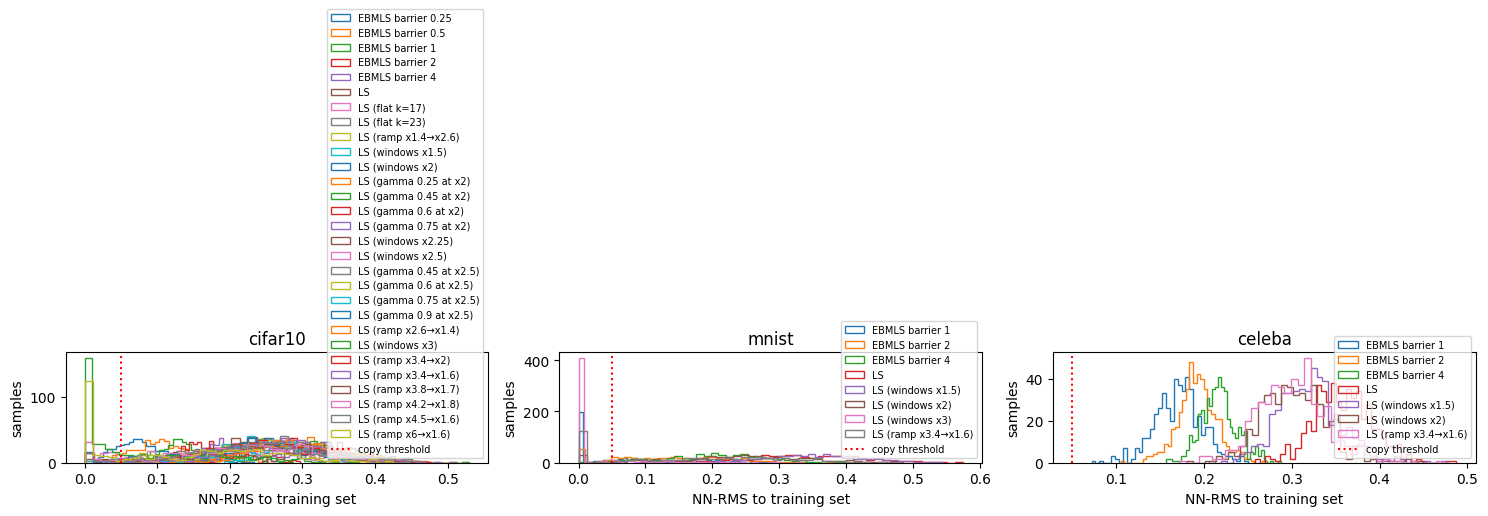

In [8]:
fig, axes = plt.subplots(1, len(DSETS), figsize=(5 * len(DSETS), 3.6), squeeze=False)
for ax, d in zip(axes[0], DSETS):
    for r in sorted([r for r in sel(dataset=d) if r['method'] != 'real'],
                    key=lambda r: (r['method'], r['mult'], r['barrier'] or 0)):
        p = r['dir'] / 'nn_rms.pt'
        if p.exists():
            ax.hist(torch.load(p).numpy(), bins=40, histtype='step', label=r['config'])
    ax.axvline(0.05, c='r', ls=':', label='copy threshold')
    ax.set_xlabel('NN-RMS to training set'); ax.set_ylabel('samples')
    ax.set_title(d); ax.legend(fontsize=7)
fig.tight_layout()

## Figure 5 — samples

/tmp/ipykernel_70561/1721597253.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  full = torch.load(r['dir'] / 'samples_uint8.pt')


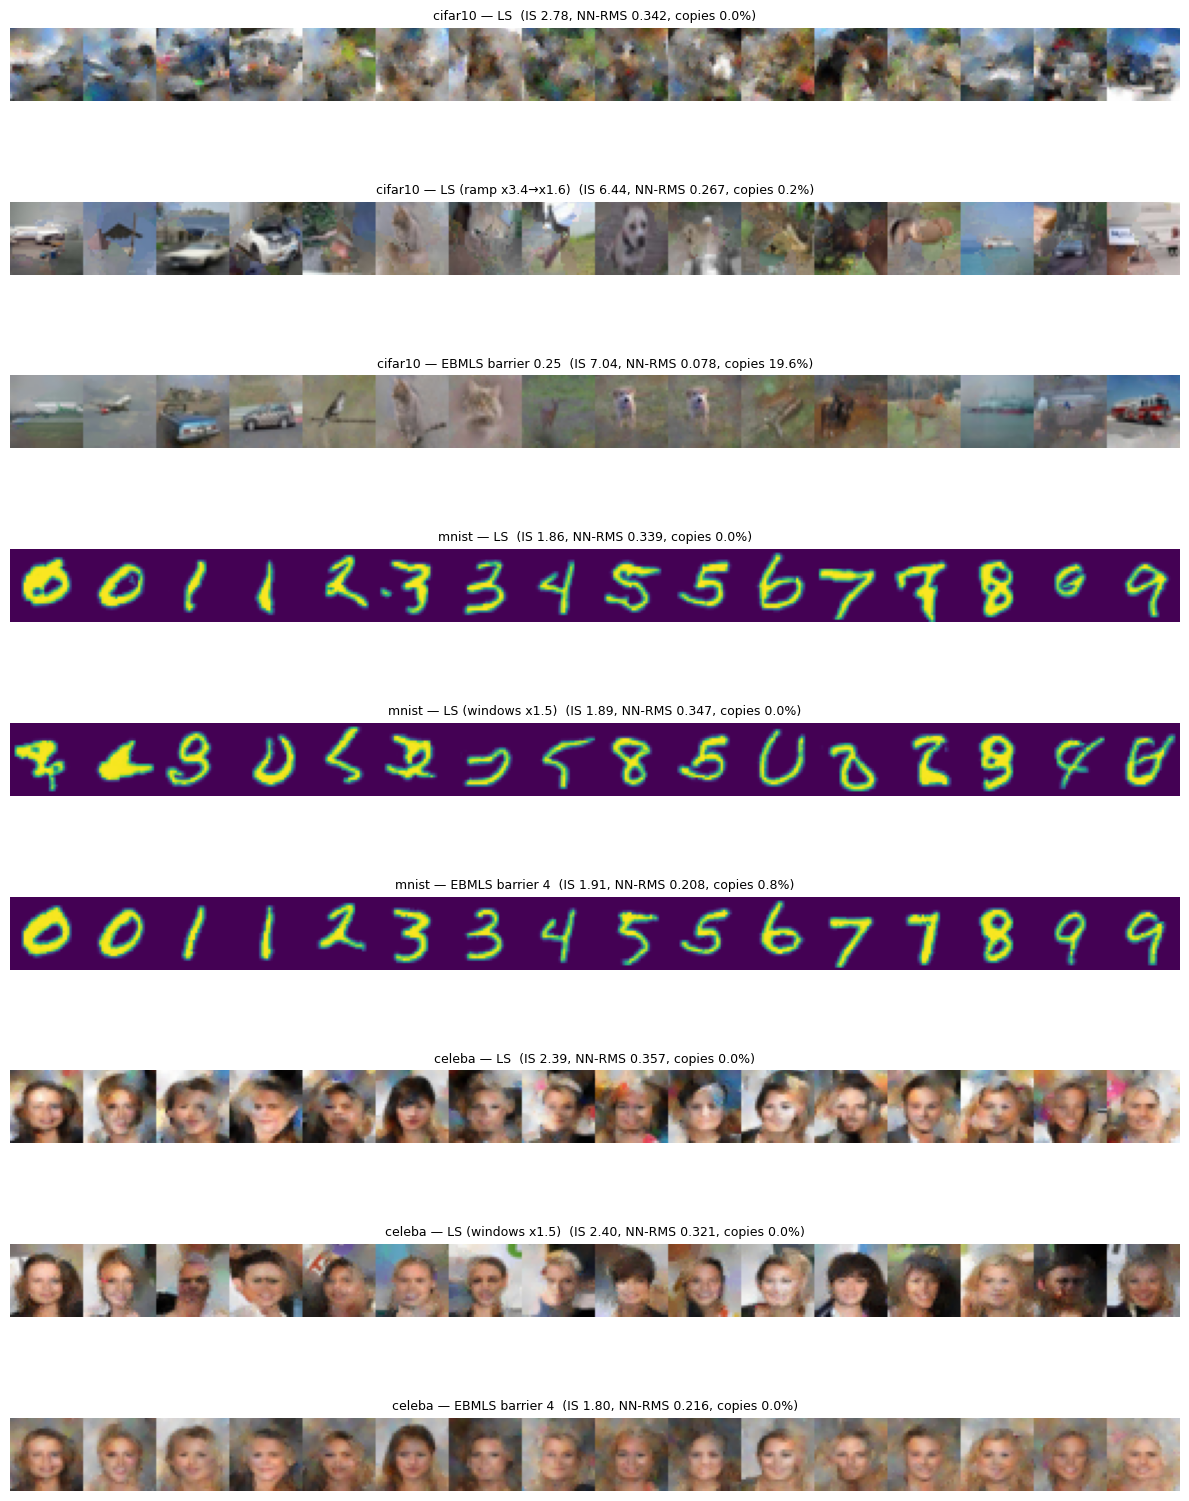

In [9]:
picks = []
for d in DSETS:
    nocopy = [r for r in sel(dataset=d, method='LS') if (r['copy_fraction'] or 0) < 0.01]
    picks += sel(dataset=d, family='LS', mult=1.0)[:1]                                   # baseline
    picks += sorted(nocopy, key=lambda r: -r['IS_mean'])[:1]                             # best non-copying LS
    picks += sorted(sel(dataset=d, method='EBMLS'), key=lambda r: -r['IS_mean'])[:1]     # best EBMLS
picks = [r for i, r in enumerate(picks) if r['dir'] not in [q['dir'] for q in picks[:i]]]
fig, axes = plt.subplots(len(picks), 1, figsize=(12, 1.8 * len(picks)), squeeze=False)
for ax, r in zip(axes[:, 0], picks):
    full = torch.load(r['dir'] / 'samples_uint8.pt')
    u8 = full[torch.linspace(0, len(full) - 1, 16).long()]  # spread over classes, not the first 16
    ax.imshow(np.concatenate(list(u8.permute(0, 2, 3, 1).numpy()), axis=1))
    ax.set_axis_off()
    ax.set_title(f"{r['dataset']} — {r['config']}  (IS {r['IS_mean']:.2f}, "
                 f"NN-RMS {r['nn_rms_median']:.3f}, copies {r['copy_fraction']:.1%})", fontsize=9)
fig.tight_layout()

## Config and provenance

In [10]:
print(json.dumps({
    'model_code_commit': '2c2dc90 (MLS + entropy barrier), harness 2aeebca (scale_multiplier control)',
    # cwd=, not `git -C`: the stock Sherlock git is 1.8.3.1 and has no -C.
    'notebook_built_at': subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT),
                                        capture_output=True, text=True).stdout.strip(),
    'seeds': '0 everywhere; 1 for the two CIFAR-10 repeat runs',
    'nsamples': 500, 'isc_splits': 5, 'genbatch': '50 (20 or 10 for the large-window reruns)',
    'scorebatchsize': '512 (128 or 64 for the large-window reruns)',
    'schedule': 'cosine', 'temperature': 1.0, 'barrier_mode': 'image',
    'cifar10': 'conditional, scales_CIFAR10_ResNet_zeros_conditional.pt, all 50k train images',
    'mnist': 'unconditional, scales_MNIST_ResNet_zeros.pt',
    'celeba': 'unconditional, --max_samples 50000, genbatch 10 / scorebatch 96 (OOM at 50/512)',
    'candidates': 'geomspace(k1+2, 2*image_size-1, 10), odd; image-size independent',
}, indent=1))
seen = set()
for r in RUNS:
    key = (r['dataset'], r['config'])
    if key not in seen and r['method'] != 'real':
        seen.add(key)
        print(f"{r['dataset']:8s} {r['config']:22s} {r['scales']}")

{
 "model_code_commit": "2c2dc90 (MLS + entropy barrier), harness 2aeebca (scale_multiplier control)",
 "notebook_built_at": "b3f6d99",
 "seeds": "0 everywhere; 1 for the two CIFAR-10 repeat runs",
 "nsamples": 500,
 "isc_splits": 5,
 "genbatch": "50 (20 or 10 for the large-window reruns)",
 "scorebatchsize": "512 (128 or 64 for the large-window reruns)",
 "schedule": "cosine",
 "temperature": 1.0,
 "barrier_mode": "image",
 "cifar10": "conditional, scales_CIFAR10_ResNet_zeros_conditional.pt, all 50k train images",
 "mnist": "unconditional, scales_MNIST_ResNet_zeros.pt",
 "celeba": "unconditional, --max_samples 50000, genbatch 10 / scorebatch 96 (OOM at 50/512)",
 "candidates": "geomspace(k1+2, 2*image_size-1, 10), odd; image-size independent"
}
cifar10  LS                     [3, 3, 3, 3, 5, 5, 5, 7, 7, 7, 7, 9, 9, 11, 11, 13, 15, 17, 17, 17]
cifar10  LS (flat k=17)         [17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17]
cifar10  LS (flat k=23)        

## Reading of the result

**1. The multilayer layer does not pay for itself — it is dominated on both metrics.** Both
families walk the same trade-off curve toward the real data as they drift onto the training set,
and at every matched memorization level plain single-layer LS is better:

| at matched copy fraction | EBMLS | LS (wider windows) |
|---|---|---|
| ~0% copies | barrier 1.0 → IS 3.30, **FID 200.7** | ×2 → IS 6.29, **FID 94.0** |
| ~15–20% copies | barrier 0.25 → IS 7.04 (19.6%), **FID 97.9** | ×2.5 → IS 7.78 (14.6%), **FID 67.8** |

FID makes the verdict sharper than IS did. EBMLS at barrier 1.0 *beat* the LS baseline on IS
(3.30 vs 2.78) but is **worse than it on FID** (200.7 vs 188.7) — that apparent gain was IS
rewarding proximity to the training set, not better samples. And LS ×2, which copies nothing at
all, has a better FID (94.0) than the most memorizing EBMLS setting (97.9 at 19.6% copies).
There is no region of Figure 2 where the second layer wins.

**2. Why it loses is structural, not a tuning failure.** Layer 2's weights sum to 1 at each pixel,
so $\hat{x}_1 + \delta$ is exactly the layer-2 posterior mean over whole training images — layer 2
*replaces* layer 1's estimate rather than refining it, with layer 1 surviving only through the
weights. Widening its window therefore walks straight to "output a training image", which is why
its memorization rises faster than its IS. Making the second layer genuinely additive (a residual
that cannot represent a single training image on its own) is the change worth trying next.

**3. The real win is window width, and it generalizes.** The scales file is far from optimal.
Uniformly scaling every per-step window by 2 gives, with **zero samples inside the copy
threshold**:

| | baseline → ×2 (IS) | baseline → ×2 (FID) |
|---|---|---|
| CIFAR-10 | 2.78 → **6.29** | 188.7 → **94.0** |
| CelebA | 2.39 → 2.34 (flat) | 128.3 → **79.4** |
| MNIST | 1.86 → 1.92 | 19.0 → 17.0 |

CIFAR-10 is reproduced across seeds (IS 2.777/2.857 at ×1, 6.286/6.073 at ×2; FID 188.7/190.4 and
94.0/93.0), so the gain is many times the seed spread. **CelebA is the case that needed FID:** its
IS is flat, which looked like a failure to generalize, but FID improves by 38%. The win is real
there and IS simply could not see it. MNIST moves little either way and remains the least
informative of the three. Past ×2 the gains stop being free — ×2.5 copies 15% of samples and ×3
copies 51% — so **×2 is the usable operating point.**

**4. The window schedule has to be widened coherently.** Applying ×2 to only the low-noise half of
the schedule gives IS 4.00, only the high-noise half gives 3.06, but both halves together give
6.29 — far more than the sum of the parts (+3.51 vs +1.50 of separate gains). A schedule that is
wide at some noise levels and narrow at others is worse than either consistent choice, so this is
a property of the trajectory rather than of any individual step.

**5. But coherent does not mean uniform: tilting the schedule beats ×2 outright.** Ramping the
multiplier down from 3.4 at $t=0$ to 1.6 at $t=1$ — i.e. loading the extra width onto the
low-noise end and *flattening* the base schedule — dominates the uniform family on CIFAR-10 at
matched memorization, reproduced across two seeds:

| schedule | seed | NN-RMS | IS ↑ | FID ↓ | copies |
|---|---|---|---|---|---|
| uniform ×2 | 0 / 1 | 0.270 / 0.274 | 6.29 / 6.07 | 93.96 / 93.04 | 0.000 / 0.000 |
| **ramp 3.4→1.6** | 0 / 1 | 0.267 / 0.271 | **6.44 / 6.31** | **83.27 / 86.08** | 0.002 / 0.000 |

Same distance to the training set, same (≈zero) copy fraction, ~9 FID better against a ~1 FID
seed spread. The up-ramp is the control and it fails: 1.4→2.6 gives FID 89.8 at NN-RMS 0.227,
*worse* than the uniform curve interpolated to the same x (≈77). So the direction of the tilt
matters and it runs against the coarse-to-fine intuition — the base schedule is already too steep,
and the fine-detail steps are the ones starved of context. The steeper down-ramps keep dominating
(3.8→1.7 → FID 75.6 at NN-RMS 0.252 vs ×2.25's 80.8 at 0.240) but start buying it with copies, so
**ramp 3.4→1.6 is the new zero-copy operating point on CIFAR-10, replacing uniform ×2.**

**6. Flattening is not the mechanism either.** A flat schedule (`--flat_k`: the same window at
every step, the down-ramp's limit) is no better than uniform, and at the zero-copy point it is
worse — $k=17$ gives FID 99.0 at NN-RMS 0.268, against 94.0 for uniform ×2 and 83.3 for the ramp
at the same distance. $k=23$ does beat uniform ×2.25 (76.5 at 0.237 vs 80.8 at 0.240) but already
copies 4.4% of samples. Both limits of the shape family therefore fail — steepening (the up-ramp)
and flattening — so the coarse-to-fine ordering earns its keep and the optimum is a *partial*
compression of the base schedule.

**7. Compressing the schedule's range is a second, FID-only win.** `--scale_gamma` raises the base
windows to a power $\gamma$ about their geometric mean, so $\gamma=1$ is exactly the uniform
multiplier and $\gamma=0$ the flat schedule at the same level. At $m=2$:

| $\gamma$ | 0.75 | 0.60 | 0.45 | 0.25 |
|---|---|---|---|---|
| NN-RMS | 0.288 | 0.289 | 0.291 | 0.290 |
| IS ↑ | 5.17 | 5.15 | 5.02 | 4.94 |
| FID ↓ | **101.8** | 103.6 | 105.3 | 110.1 |

Every one of them is far above the uniform curve, which interpolated to NN-RMS 0.289 gives FID
≈121 — compressing the range costs ≈430 FID per unit NN-RMS against the uniform multiplier's
≈1400, so it is much the cheaper way to buy distance from the training set. **IS says the
opposite** (5.17 → 4.94, all below the uniform curve's ≈5.2): the third time in this sweep that
IS and FID disagree, and I recorded the family as negative off the IS numbers before the FID
landed.

Repeating the sweep at the *champion's* level rather than at $m=2$ settles what $\gamma$ is
actually doing. At $m=2.5$ ($k_{geo}=18.8$, against the ramp's 18.5):

| $\gamma$ | $k_0/k_{max}$ | NN-RMS | IS ↑ | FID ↓ | copies |
|---|---|---|---|---|---|
| 0.90 | 9/39 | 0.231 | 6.99 | 73.0 | 0.058 |
| 0.75 | 9/35 | 0.248 | 6.49 | 80.4 | 0.012 |
| 0.60 | 11/31 | 0.262 | 6.23 | **85.5** | 0.004 |
| 0.45 | 13/27 | 0.275 | 5.86 | 88.1 | 0.002 |

$\gamma=0.60$ at $m=2.5$ reproduces the ramp 3.4→1.6 schedule to within a pixel at both ends
($k_0$ 11, $k_{max}$ 31, $k_{geo}$ 18.9 against 11/31/18.5) and reproduces its metrics (FID 85.5 at
NN-RMS 0.262, against 83.3 at 0.267). So **(level, compression) is the right parameterization and
the hand-tuned ramp was a point inside it all along** — which is the useful part of this result,
because it replaces a two-endpoint hand-tune with one knob for *where* you sit on the frontier and
one for *how* the width is distributed.

What it does not do is move the frontier. The $\gamma$ curve at fixed level traces the same
FID-vs-NN-RMS trade-off as the down-ramp family — marginally below it in the middle, above it at
the de-memorized end ($\gamma=0.45$: 88.1 at 0.275, against ≈92 interpolated for the ramps and ≈97
for uniform) — and nothing in it displaces ramp 3.4→1.6 at zero copies. The gap that *is* robust
is between shape *classes*: compressed and tilted schedules sit 7–10 FID below uniform and flat at
every matched training-set distance, in two independent parameterizations. That gap, not which
family draws it, is the transferable result.

**8. Neither end of the schedule is a free knob on its own.** The $k_{geo}$/$k_{max}$ table
suggested memorization tracks the schedule's *peak* window, which would make the low-noise end
free quality. It does not: at fixed peak ($m_1=1.6$), raising $m_0$ from 3.4 to 4.5 to 6.0 drives
NN-RMS 0.267 → 0.235 → 0.163 and copies 0.2% → 5.4% → 31%. And at matched memorization the
single-ended pushes lose to the balanced ramp:

| schedule | NN-RMS | IS ↑ | FID ↓ | copies |
|---|---|---|---|---|
| ramp 4.5→1.6 (low-noise end up) | 0.235 | 6.60 | 73.4 | 0.054 |
| ramp 3.4→2.0 (peak up) | 0.238 | 6.93 | 73.9 | 0.042 |
| ramp 4.2→1.8 (both) | 0.236 | **7.20** | **71.0** | 0.092 |
| flat k=23 | 0.237 | 6.86 | 76.5 | 0.044 |
| uniform ×2.25 | 0.240 | 6.80 | 80.8 | 0.028 |

Both single-ended pushes still beat flat and uniform on FID, and at matched *copy fraction* they
beat 4.2→1.8 as well, but nothing here displaces **ramp 3.4→1.6 as the zero-copy operating
point**. Together with the super-additivity in point 4, the schedule behaves as one object: the
ends have to move together.

**9. The tilt transfers to CelebA and is neutral on MNIST.** Running the same 3.4→1.6 ramp
unchanged on the other two datasets:

| dataset | schedule | NN-RMS | IS ↑ | FID ↓ | copies |
|---|---|---|---|---|---|
| CelebA | uniform ×2 | 0.302 | 2.344 | 79.37 | 0.000 |
| CelebA | **ramp 3.4→1.6** | 0.301 | 2.344 | **70.02** | 0.000 |
| MNIST | uniform ×2 | 0.240 | 1.918 | 17.03 | 0.078 |
| MNIST | ramp 3.4→1.6 | 0.191 | 1.949 | 16.59 | 0.250 |

CelebA is the cleanest comparison in the whole sweep — NN-RMS 0.301 against 0.302 and zero copies
in both — and FID drops by 9.4, the same size of win as on CIFAR-10. **MNIST shows no effect:** the
ramp lands at FID 16.59 with 25% copies where the uniform curve interpolated to the same NN-RMS
gives ≈16.8 with ≈24% copies, so it is on the uniform frontier, not above it. MNIST has been
uninformative throughout (its whole FID range is 19.0→15.8 against a real-image floor of 12.2), so
this is weak evidence either way rather than a counterexample.

**10. The barrier does find a sensible schedule.** Nothing imposes one, yet the selected layer-2
window runs from the full image at high noise down to $k=0$ (layer 2 off) at low noise (Figure 3).
The coarse-to-fine ordering is a real finding even though the layer-2 update rule is not worth its
cost.

**Caveats.** 500 samples understates IS (real CIFAR-10 scores 8.75 here against ~11 in the
literature) and inflates FID (the real-vs-real floor is 54.9 on CIFAR-10, 32.8 on CelebA, 12.2 on
MNIST rather than 0); only relative comparisons at equal sample count are meaningful. The layer-2
posterior uses $\sigma^2=b_t^2/a_t^2$, the noise scale of $x/a_t$, even though it conditions on the
already-denoised $\hat{x}_1$ whose error is smaller and not isotropic — hshunt has flagged this
posterior as incorrect and is supplying the corrected form, which will change the deltas and the
entropies the barrier thresholds on.